Iteration: 1 Best Fitness: 20.061591
Iteration: 2 Best Fitness: 19.985226
Iteration: 3 Best Fitness: 19.817619
Iteration: 4 Best Fitness: 19.78779
Iteration: 5 Best Fitness: 19.78779
Iteration: 6 Best Fitness: 19.760491
Iteration: 7 Best Fitness: 19.760491
Iteration: 8 Best Fitness: 19.760491
Iteration: 9 Best Fitness: 19.756503
Iteration: 10 Best Fitness: 19.756503
Iteration: 11 Best Fitness: 19.756503
Iteration: 12 Best Fitness: 19.737008
Iteration: 13 Best Fitness: 19.737008
Iteration: 14 Best Fitness: 19.708629
Iteration: 15 Best Fitness: 19.708629
Iteration: 16 Best Fitness: 19.696403
Iteration: 17 Best Fitness: 19.696403
Iteration: 18 Best Fitness: 19.688801
Iteration: 19 Best Fitness: 19.688801
Iteration: 20 Best Fitness: 19.688801
Iteration: 21 Best Fitness: 19.688801
Iteration: 22 Best Fitness: 19.688801
Iteration: 23 Best Fitness: 19.688801
Iteration: 24 Best Fitness: 19.688801
Iteration: 25 Best Fitness: 19.688801
Iteration: 26 Best Fitness: 19.688801
Iteration: 27 Best Fitn

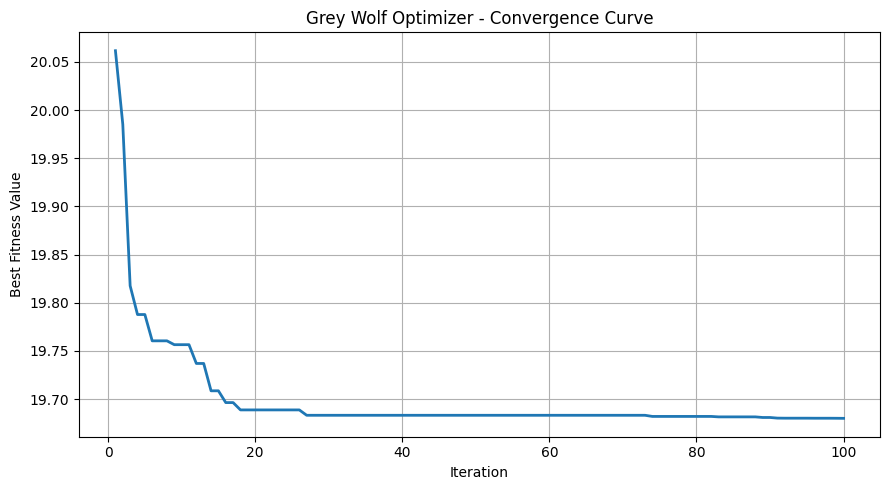

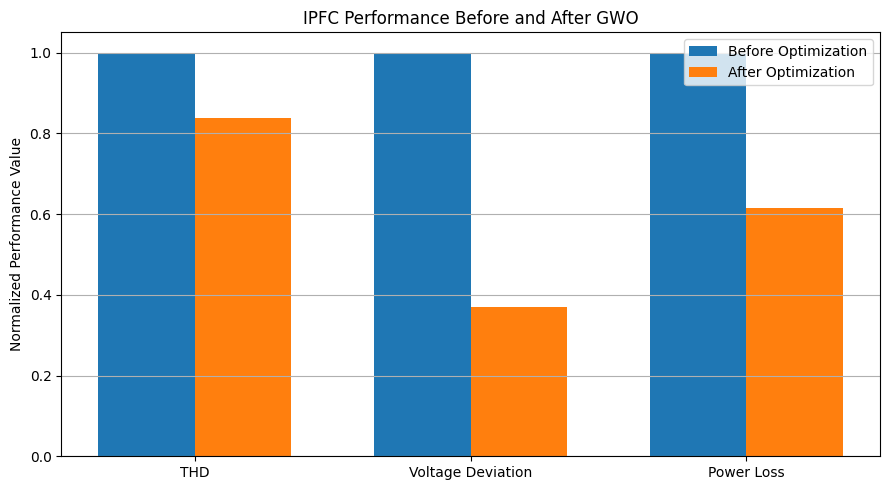

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# Grey Wolf Optimizer for IPFC Controller Optimization

np.random.seed(42)

# Number of wolves and iterations
n_wolves = 30
max_iterations = 100

# Controller parameters:
# Kp = Proportional gain
# Ki = Integral gain
# H  = Hysteresis control parameter

dimensions = 3

# Search space (normalized demonstration values)
lower_bound = np.array([0.0, 0.0, 0.0])
upper_bound = np.array([1.0, 1.0, 1.0])

# Objective function weights
alpha_weight = 1.0
beta_weight = 100.0
gamma_weight = 1.0


# Calculate system performance
def calculate_metrics(x):

    kp, ki, h = x

    # Illustrative performance model
    # These equations are demonstration assumptions,
    # not equations supplied by the research paper.

    thd = (
        16.68
        + 8 * (kp - 0.65)**2
        + 5 * (ki - 0.45)**2
        + 3 * (h - 0.35)**2
    )

    voltage_deviation = (
        0.01
        + 0.04 * (kp - 0.65)**2
        + 0.03 * (ki - 0.45)**2
        + 0.02 * (h - 0.35)**2
    )

    power_loss = (
        2.0
        + 3 * (kp - 0.65)**2
        + 2 * (ki - 0.45)**2
        + 1.5 * (h - 0.35)**2
    )

    return thd, voltage_deviation, power_loss


# Fitness function
def fitness(x):

    thd, vd, pl = calculate_metrics(x)

    return (
        alpha_weight * thd
        + beta_weight * vd
        + gamma_weight * pl
    )


# Initialize wolves randomly
wolves = np.random.uniform(
    lower_bound,
    upper_bound,
    (n_wolves, dimensions)
)

# Initialize alpha, beta and delta
alpha_pos = np.zeros(dimensions)
beta_pos = np.zeros(dimensions)
delta_pos = np.zeros(dimensions)

alpha_score = float("inf")
beta_score = float("inf")
delta_score = float("inf")

convergence = []


# Grey Wolf Optimization
for iteration in range(max_iterations):

    # Evaluate every wolf
    for i in range(n_wolves):

        wolves[i] = np.clip(
            wolves[i],
            lower_bound,
            upper_bound
        )

        score = fitness(wolves[i])

        # Update Alpha
        if score < alpha_score:

            delta_score = beta_score
            delta_pos = beta_pos.copy()

            beta_score = alpha_score
            beta_pos = alpha_pos.copy()

            alpha_score = score
            alpha_pos = wolves[i].copy()

        # Update Beta
        elif score < beta_score:

            delta_score = beta_score
            delta_pos = beta_pos.copy()

            beta_score = score
            beta_pos = wolves[i].copy()

        # Update Delta
        elif score < delta_score:

            delta_score = score
            delta_pos = wolves[i].copy()

    # Decreasing control parameter
    a = 2 - iteration * (2 / max_iterations)

    # Update position of each wolf
    for i in range(n_wolves):

        for j in range(dimensions):

            # Alpha wolf calculation
            r1 = np.random.random()
            r2 = np.random.random()

            A1 = 2 * a * r1 - a
            C1 = 2 * r2

            D_alpha = abs(
                C1 * alpha_pos[j] - wolves[i][j]
            )

            X1 = alpha_pos[j] - A1 * D_alpha

            # Beta wolf calculation
            r1 = np.random.random()
            r2 = np.random.random()

            A2 = 2 * a * r1 - a
            C2 = 2 * r2

            D_beta = abs(
                C2 * beta_pos[j] - wolves[i][j]
            )

            X2 = beta_pos[j] - A2 * D_beta

            # Delta wolf calculation
            r1 = np.random.random()
            r2 = np.random.random()

            A3 = 2 * a * r1 - a
            C3 = 2 * r2

            D_delta = abs(
                C3 * delta_pos[j] - wolves[i][j]
            )

            X3 = delta_pos[j] - A3 * D_delta

            # Final position update
            wolves[i][j] = (X1 + X2 + X3) / 3

    # Store best fitness for convergence graph
    convergence.append(alpha_score)

    print(
        "Iteration:", iteration + 1,
        "Best Fitness:", round(alpha_score, 6)
    )


# Display optimized parameters
print("\n----- OPTIMIZED IPFC PARAMETERS -----")

print("Optimal Kp:", round(alpha_pos[0], 5))
print("Optimal Ki:", round(alpha_pos[1], 5))
print("Optimal H :", round(alpha_pos[2], 5))

# Calculate performance before optimization
initial_parameters = np.array([0.1, 0.1, 0.1])

before = calculate_metrics(initial_parameters)
after = calculate_metrics(alpha_pos)

print("\n----- PERFORMANCE COMPARISON -----")

print("\nBefore Optimization")
print("THD:", round(before[0], 4), "%")
print("Voltage Deviation:", round(before[1], 6))
print("Power Loss:", round(before[2], 4))

print("\nAfter Optimization")
print("THD:", round(after[0], 4), "%")
print("Voltage Deviation:", round(after[1], 6))
print("Power Loss:", round(after[2], 4))


# Plot 1: GWO convergence graph
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, max_iterations + 1),
    convergence,
    linewidth=2
)

plt.xlabel("Iteration")
plt.ylabel("Best Fitness Value")
plt.title("Grey Wolf Optimizer - Convergence Curve")
plt.grid(True)

plt.tight_layout()
plt.show()


# Plot 2: Performance comparison
metrics = ["THD", "Voltage Deviation", "Power Loss"]

before_values = list(before)
after_values = list(after)

# Normalize values for visual comparison
before_normalized = np.array(before_values) / np.array(before_values)
after_normalized = np.array(after_values) / np.array(before_values)

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    before_normalized,
    width,
    label="Before Optimization"
)

plt.bar(
    x + width / 2,
    after_normalized,
    width,
    label="After Optimization"
)

plt.xticks(x, metrics)
plt.ylabel("Normalized Performance Value")
plt.title("IPFC Performance Before and After GWO")
plt.legend()
plt.grid(axis="y")

plt.tight_layout()
plt.show()
